[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D7_truco_kernel.ipynb)

# D7 · El truco del kernel, a mano

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód I + D6).** El dual del SVM solo usa productos punto $x^{(i)}\cdot x^{(k)}$.

**Supuestos.** El algoritmo usa los datos solo por productos punto; $K$ es un kernel válido (matriz de Gram semidefinida positiva). Las variables están estandarizadas (RBF usa distancias).

**La idea.** $(x\cdot z+1)^2=\phi(x)\cdot\phi(z)$ con $\phi(x)=(x_1^2,x_2^2,\sqrt2x_1x_2,\sqrt2x_1,\sqrt2x_2,1)$. Y en RBF, $\gamma$ fija el radio de influencia de cada punto (≈ $1/\sqrt\gamma$).

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
LOG10_GAMMA = 0.0   # γ = 10**LOG10_GAMMA para el kernel RBF

## La identidad, con números

máx |K − φ·φ| en 1000 pares = 1.07e-14
ejemplo x=(1,2), z=(3,−1): 4 3.9999999999999982


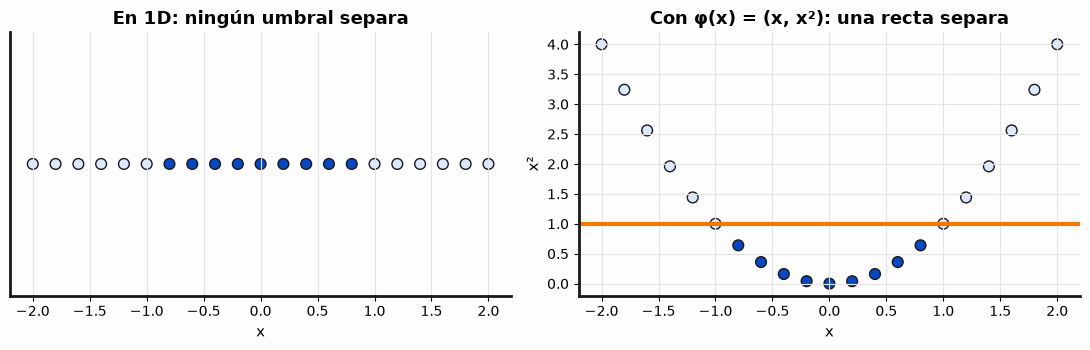

eigenvalor mínimo de la matriz de Gram RBF (γ=1): -5.01e-15  (≥ 0 salvo redondeo: kernel válido)
γ = 1  radio ≈ 1/√γ = 1.00   exactitud entrenamiento = 0.93   validación = 0.96   SV = 67


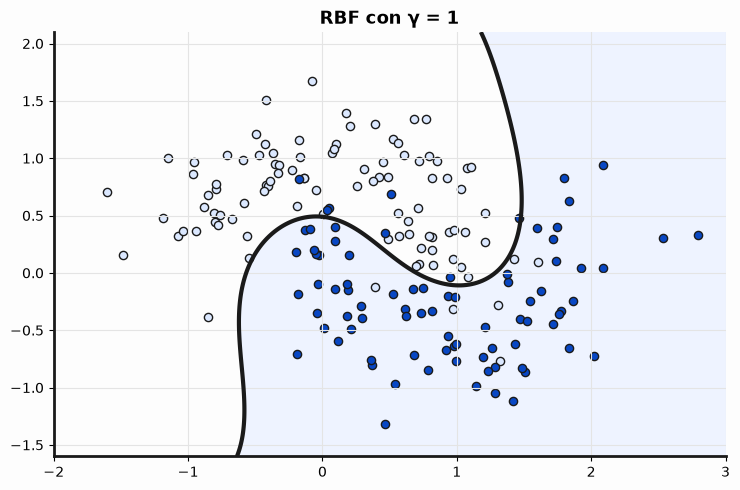

In [3]:
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from dammg_utils import phi_poli2

# 1) El kernel polinomial a mano, en 1000 pares
rng = np.random.default_rng(7)
P, Q = rng.normal(size=(1000, 2)), rng.normal(size=(1000, 2))
K_directo = (np.sum(P * Q, axis=1) + 1) ** 2
K_phi = np.array([phi_poli2(p) @ phi_poli2(q) for p, q in zip(P, Q)])
print(f"máx |K − φ·φ| en 1000 pares = {np.abs(K_directo - K_phi).max():.2e}")
assert np.allclose(K_directo, K_phi)
print("ejemplo x=(1,2), z=(3,−1):", (np.dot([1, 2], [3, -1]) + 1) ** 2, phi_poli2(np.array([1., 2.])) @ phi_poli2(np.array([3., -1.])))

# 2) Elevar para separar (de 1D a 2D)
x1 = np.linspace(-2, 2, 21); c1 = np.abs(x1) < 1
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(x1, 0 * x1, c=np.where(c1, C["w"], C["datos"]), edgecolor=C["tinta"], s=60)
ax[0].set(yticks=[], title="En 1D: ningún umbral separa", xlabel="x")
ax[1].scatter(x1, x1**2, c=np.where(c1, C["w"], C["datos"]), edgecolor=C["tinta"], s=60)
ax[1].axhline(1, color=C["lambda"], linewidth=3)
ax[1].set(title="Con φ(x) = (x, x²): una recta separa", xlabel="x", ylabel="x²")
fig.tight_layout(); plt.show()

# 3) RBF: el papel de γ
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=0)
Xtr, Xva, ytr, yva = train_test_split(Xm, ym, test_size=0.4, random_state=0)
G = np.exp(-1.0 * np.sum((Xtr[:, None] - Xtr[None]) ** 2, axis=2))
print(f"eigenvalor mínimo de la matriz de Gram RBF (γ=1): {np.linalg.eigvalsh(G).min():.2e}  (≥ 0 salvo redondeo: kernel válido)")

def demo(log10_gamma=LOG10_GAMMA):
    g = 10 ** log10_gamma
    svm = SVC(kernel="rbf", gamma=g, C=1.0).fit(Xtr, ytr)
    print(f"γ = {g:.3g}  radio ≈ 1/√γ = {1/np.sqrt(g):.2f}   exactitud entrenamiento = {svm.score(Xtr, ytr):.2f}   validación = {svm.score(Xva, yva):.2f}   SV = {len(svm.support_)}")
    xx, yy = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.6, 2.1, 250))
    F = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.contourf(xx, yy, F > 0, levels=[-0.5, 0.5, 1.5], colors=[C["papel"], "#eef3ff"])
    ax.contour(xx, yy, F, levels=[0], colors=[C["tinta"]], linewidths=3)
    ax.scatter(*Xtr[ytr == 0].T, color=C["datos"], edgecolor=C["tinta"], s=35)
    ax.scatter(*Xtr[ytr == 1].T, color=C["w"], edgecolor=C["tinta"], s=35)
    ax.set(title=f"RBF con γ = {g:.3g}", xlim=(-2, 3), ylim=(-1.6, 2.1))
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: con $\gamma=100$, ¿qué pasa con la exactitud de entrenamiento y la de validación? ¿Y con $\gamma=0.01$?

Respuesta esperada: con $\gamma$ grande, entrenamiento ≈ 1 y validación baja (islas alrededor de cada punto: sobreajuste). Con $\gamma$ chico la frontera es casi recta (subajuste).

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, log10_gamma=W.FloatSlider(value=LOG10_GAMMA, min=-2, max=2.5, step=0.25, description='log₁₀ γ', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')